# Home assigment 2

Please give your name below:

In [1]:
name='Lê Huỳnh Thiện Nhân'

## Exercise 2

Now you will put together the pieces you learnt in previous labs in order to write a continuous energy Monte Carlo particle transport simulation of a Uranium sphere! Your goal is to estimate the k-effective and to try to find the critical radius of a U-235 sphere. 

Your assumptions:

- The geometry is a sphere
- The sphere is made of pure U-235.
- You only care about the following reactions: capture, fission and elastic scattering 
- All scattering is isotropic in the CM frame.
- Neutrons emerge isotropically from fission.
- Download the pointwise cross sections and the energy dependent nubar data (hint: you can use https://www-nds.iaea.org/).
- You can neglect that in a fission event the number of generated neutrons is stochastic, and assume that always nubar neutrons are created.
- For the prompt neutron energies you can sample the Watt-distribution (see lecture notes, or Datalab 4)
- You do not need to track time (thus all neutrons can be considered to be prompt)
- Initially launch neutrons from the center of the sphere, then store fission sites, and later sample the new fission sites from this "bank".

Your tasks:

1. Plot the data you downloaded: the cross section data and the nubar data.
2. Complete the function `run()` in order to estimate the k-eigenvalue of a sphere with a continous energy 3D Monte Carlo particle transport simulation. You are encouraged to separate parts into other functions as you saw in Datalab 5b (for example the direction transformations, Watt-spectrum sampling etc). You can include other input parameters and set default values if you feel needed. For each neutron generation estimate the k-eigenvalue based on the initial number of neutrons and the new neutrons after the generation.
3. Modify the return list in order to return and plot other data
    - Plot the k-eigenvalue estimate vs the generation number
    - Plot how the estimated mean k-eigenvalue converges. (use such figures to argue about reasonable values for `NGEN`, `NPG`, `NSKIP`). 
4. Investigate how the k-eigenvalue depends on the radius of the sphere. Visualize this with matplotlib.
5. Find the critical radius. You can do this either with manual trial and error, or use an optimization method.


Hints: in this exercise you have to merge your knowledge from datalab 5a (ie. batchwise estimation of k-effective) and from datalab 5b (ie. tracking neutrons). If you are not sure about the validity of your results you can compare your findings with the values of critical radii from [Wikipedia](https://en.wikipedia.org/wiki/Critical_mass). Try to have similar order of magnitude results.

To be fair, in a real MC criticality calculation, the initial number of neutrons per cycle also fluctuates, and the k-eigenvalue is calculated with some power iteration. In that case some care needs to be taken to renormalize the number of events to be placed in the bank, in order to have more or less the same amount of starting neutrons in each batch, otherwise sub and supercritical systems would be problematic to be simulated (here p200-225 gives some details on that: https://mcnp.lanl.gov/pdf_files/la-ur-16-29043.pdf). You don't need to worry about these. We are satisfied with a simpler approach. Rather you will initiate the same amount of neutrons in each cycle, regardless how many were produced before, and we place every fission site into the bank, and sample the locations from that. We also do not require an initial guess for the k-eigenvalue (as you can see in the link for the power iteration based method, an initial guess is needed). 

In the first few cycles when we launch neutrons only from the center, we will probably underestimate leakage, so the estimates of $k$ will be biased. Therefore NSKIP just means that the first NSKIP number of cycle estimates of the k-effective should not be taken into account when calculating the mean of the k-effective, since the spatial distribution of the fission source is still biased by our original source location, and not spread yet throughout the geometry. Actually for this simple geometry NSKIP plays a less important role, so if you are not certain about what it is, feel free to ignore it. 

In [4]:
import openmc
openmc.config['cross_sections'] = '/home/dell/endfb-vii.1-hdf5/cross_sections.xml'
import numpy as np
import matplotlib.pyplot as plt
import os
import re

In [8]:
RHO = 18.95            # g/cm3 (density of U metal; use 18.71 for HEU if you prefer)
M_U = 235.0439         # g/mol
NA = 0.602214076       # Avogadro * 1e-24  -> N comes out in atoms/(barn cm)
N_DENS = RHO * NA / M_U
A = 233.025            # mass ratio of U-235 to neutron
WATT_A, WATT_B = 0.988, 2.249   # U-235 thermal fission Watt parameters (MeV, 1/MeV)
E_UNIT = 1e-6          # multiply file energies by this to get MeV (eV -> MeV)

def sig_extract(file):
    data = []
    with open(file, 'r') as content:
        for lines in content:
            line = lines.split()
            if len(line) == 3 and line[2] == "Lin-Lin":
                data.append([float(line[0]),float(line[1])])
    return np.array(data)
    
def nubar_extract(file):
    data = []
    with open(file, 'r') as content:
        for lines in content:
            line = lines.split()
            if len(line) == 6 and line[0] != '96':
                try:
                    data.append([float(insert_e(line[0])),float(insert_e(line[1]))])
                    data.append([float(insert_e(line[2])),float(insert_e(line[3]))])
                    data.append([float(insert_e(line[4])),float(insert_e(line[5]))])
                except ValueError:
                    continue
    return np.array(data)

def insert_e(val):
    index = max(val.rfind('+'), val.rfind('-'))
    if 'e' not in val: 
        return val[:index]+'e'+val[index:]
    else: 
        return val

def watt(E): 
    C1 = 0.453
    C2 = 0.965
    C3 = 2.29
    return C1*np.exp(-E/C2)*np.sinh(np.sqrt(C3*E))

E_grid = np.linspace(0, 20, 20001)          # MeV; the pdf beyond 20 MeV is negligible
pdf = watt(E_grid)
cdf = np.concatenate(([0.0], np.cumsum(0.5*(pdf[1:] + pdf[:-1]) * np.diff(E_grid))))
cdf /= cdf[-1]                               # normalization

def sample_watt(n, rng):
    """n fission-neutron energies in MeV."""
    return np.interp(rng.random(n), cdf, E_grid)

def run(R,NGEN,NPG,NSKIP):
    """Function to perform a criticality calculation in a U-235 sphere.
    
    Parameters
    ----------
    R : float
        Radius of the sphere
    NGEN : int
        Number of neutron generations
    NPG : int
        Number of neutrons per generation
    NSKIP : int
        Number of inactive generations which will not be taken into account for estimating the k-eigenvalue
    
    Returns
    -------
    keff : float
        The estimated mean k-eigenvalue of the system
    kstd : float
        The standard deviation of the estimated k-eigenvalue
    """
    return keff, kstd

capture = sig_extract('U235_capture.txt')
elastic = sig_extract('U235_elastic.txt')
fission = sig_extract('U235_fission.txt')
capture_e = capture[:,0]
capture_sig = capture[:,1]
elastic_e = elastic[:,0]
elastic_sig = elastic[:,1]
fission_e = fission[:,0]
fission_sig = fission[:,1]

nu = nubar_extract('U235_nubar.txt')
nu_e = nu[:,0]
nu_nubar = nu[:,1]

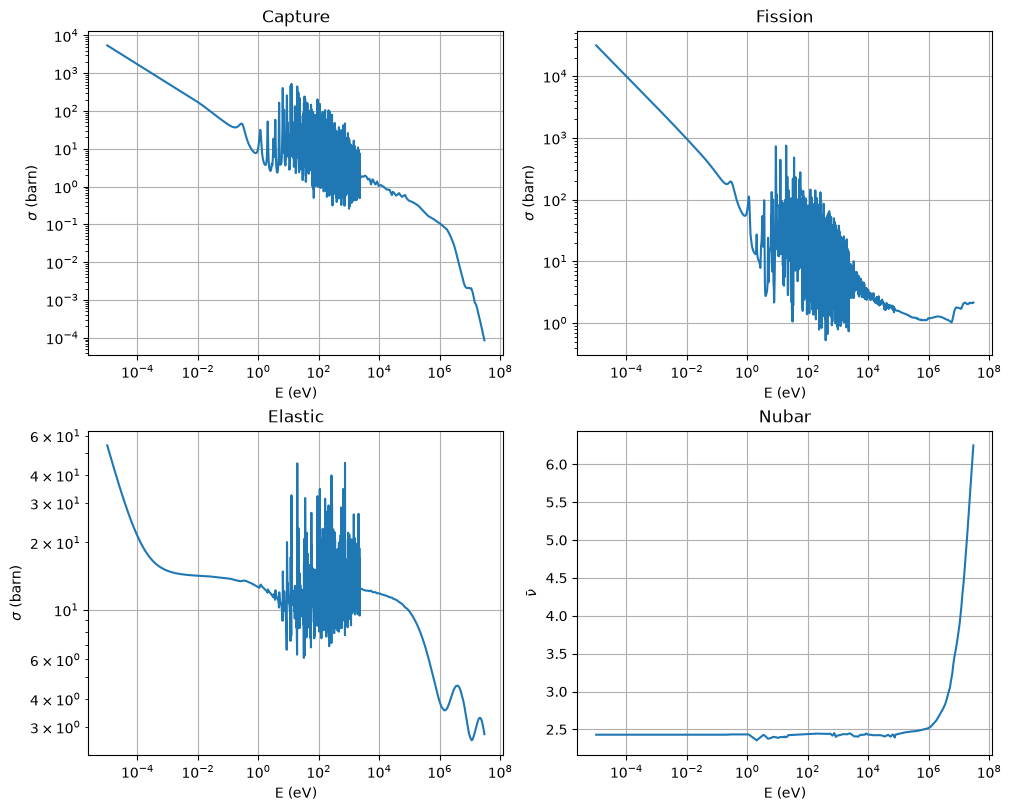

In [5]:
fig, ax = plt.subplots(2,2, figsize = (10,8), constrained_layout = True)
ax[0,0].loglog(capture_e,capture_sig)
ax[0,0].set(title = "Capture", xlabel = "E (eV)", ylabel = "$\\sigma$ (barn)")

ax[1,0].loglog(elastic_e,elastic_sig)
ax[1,0].set(title = "Elastic", xlabel = "E (eV)", ylabel = "$\\sigma$ (barn)")

ax[0,1].loglog(fission_e,fission_sig)
ax[0,1].set(title = "Fission", xlabel = "E (eV)", ylabel = "$\\sigma$ (barn)")

ax[1,1].semilogx(nu_e,nu_nubar)
ax[1,1].set(title = "Nubar", xlabel = "E (eV)", ylabel = "$\\bar\\nu$")

for a in ax.flat:
    a.grid(True)
plt.show()

In [17]:
rng = np.random.default_rng(1)
E = sample_watt(100000, rng)
print(E.mean()) 

1.9799934351905693
